# 01 · Preprocessing — Roider et al. 2020 B-Cell Lymphoma (malignant compartment)

Isolate the malignant B-lymphoma compartment, threshold thin samples by a
data-driven gap rule, integrate the strong patient-specific batch effect
(Harmony on `sample`, θ swept), embed, strip detached islands, and settle the
manifold's biology (one low-cycling body — signatures + cell cycle) **before**
the Gate-1 call. Malignant cells come only from the 9 lymphoma samples
(DLBCL/FL/tFL); the 3 reactive-lymph-node (rLN) *normal* samples contribute no
`Malignant` cells and are absent by construction. **Gate 1**: is the malignant
structure both sample-mixed and continuous? Deliverable: `processed.h5ad`,
`samples.pdf`.

In [ ]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)                       # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Roider2020_Hematologic | category: Hematologic


### Load malignant compartment

In [ ]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('per-sample malignant counts:', adata.obs['sample'].value_counts().to_dict())
print('disease composition:', adata.obs.groupby('disease', observed=True).size().to_dict())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Roider2020_Hematologic
Done.
full atlas: (35278, 24291)
malignant: (22600, 24291) | samples: 9
per-sample malignant counts: {'FL2': 3936, 'DLBCL2': 3776, 'FL3': 3196, 'DLBCL1': 3112, 'FL1': 2595, 'FL4': 2287, 'DLBCL3': 1788, 'tFL2': 1583, 'tFL1': 327}
disease composition: {'Diffuse large B cell lymphoma': 8676, 'Follicular Lymphoma': 12014, 'Transformed Follicular Lymphoma': 1910}
expression: X max 7.45 (log1p of normalize_total UMI counts)


### Sample thresholding (data-driven gap rule)
Sort per-sample malignant counts and look for a *dominant multiplicative cliff*
(a gap ≥1.5× the runner-up gap that drops a sample below ~2× the 100-cell
floor) — the signature of a spillover/doublet sample that should be cut. Absent
such a cliff, keep every sample above the 100-cell floor (enough cells per
patient for Harmony to model the batch).

In [ ]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]
top, second = srt[0], srt[1]; FLOOR = 100
dominant = (top / second >= 1.5) and (vals[gap+1] < 2*FLOOR)   # a real spillover cliff?
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff (largest gap {int(vals[gap])}->{int(vals[gap+1])} lands well above the floor) -> keep >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'FL2': np.int64(3936), 'DLBCL2': np.int64(3776), 'FL3': np.int64(3196), 'DLBCL1': np.int64(3112), 'FL1': np.int64(2595), 'FL4': np.int64(2287), 'DLBCL3': np.int64(1788), 'tFL2': np.int64(1583), 'tFL1': np.int64(327)}
gap ratios: ['3936->3776:1.04', '3776->3196:1.18', '3196->3112:1.03', '3112->2595:1.20', '2595->2287:1.13', '2287->1788:1.28', '1788->1583:1.13', '1583->327:4.84']
argmax gap 1583->327 (ratio 4.84); top/second = 3.78; dominant cliff = False
no dominant cliff (largest gap 1583->327 lands well above the floor) -> keep >= 100
kept 9/9 samples (min per-sample = 327) -> 22600 cells


### Overdispersion, PCA, Harmony integration sweep, embedding
B-cell lymphoma clones are genetically distinct per patient, so the raw
same-sample neighbour fraction is near 1.0 (severe batch effect). Sweep Harmony
θ and pick the strength past which mixing flattens.

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta,
      '(mixing improves sharply to theta=5 then flattens — theta=10 within noise of theta=5;',
      'strongest integration chosen for the strong patient-specific lymphoma batch effect, without collapsing structure)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1334 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1334
same-sample neighbour fraction | pre-Harmony 0.995 | sweep {2: 0.49, 5: 0.265, 10: 0.26}
selected theta = 10 (mixing improves sharply to theta=5 then flattens — theta=10 within noise of theta=5; strongest integration chosen for the strong patient-specific lymphoma batch effect, without collapsing structure)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and
keep only the largest connected component — stripping small physically-detached
specks while preserving the continuous body.

In [ ]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('cells after island removal:', adata.shape[0])

removed 1 cells in 1 detached islands
cells after island removal: 22599


### Manifold biology — lobe structure + cell cycle (biology before geometry)
Low-resolution Leiden to test whether the manifold splits into biologically
distinct lobes, and quantify the cycling fraction per lobe. A single
low-cycling body means the whole malignant compartment is one trajectory
object; if a proliferation lobe split off it would have to be scoped out.

In [ ]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('proliferation score per lobe:',
      adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
# single low-cycling body -> label uniformly; whole compartment is the trajectory object
adata.obs['compartment'] = 'Body'
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 22599}
overall cycling fraction: 0.107
cycling fraction per lobe: {'0': 0.107}
proliferation score per lobe: {'0': -0.064}
compartments: {'Body': 22599}


### Module scores + house linear orientation
Score the three embryonic modules (union control pool) and graph-smooth them, so
the developmental-origin pole can be located for a consistent orientation
(`X_umap_lin`) shared by every panel across 01–04. Raw scores are retained for
the deliverable panels; smoothing only aids the geometry read.

In [ ]:
import scipy.sparse as sp
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
origin_score = (S[:,0] + S[:,1]) - S[:,2]     # Gast+pSom-high / Crest-low = developmental origin

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()                     # origin pole -> left (negative x)
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'Gast/pSom-high origin pole on left; stored as X_umap_lin')

Gast: 64/81 genes present
pSom: 77/98 genes present
Crest: 88/104 genes present
manifold aspect (max/min std): 1.55
house orientation: rigid rotation +7.3deg (distances preserved), Gast/pSom-high origin pole on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity (iLISI, read on the embedding)
Per-neighbourhood iLISI (not a global scalar) plus the single-connected-component
result: samples must intermix per-neighbourhood on one continuous manifold.

In [ ]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (largest connected component; specks removed above).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 4.58 of 9 samples
9 samples share one continuous manifold (largest connected component; specks removed above).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS


### Save processed data

In [ ]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','disease','disease_subtype'}
for cc in adata.obs.columns:
    if cc in protect:
        adata.obs[cc] = adata.obs[cc].astype(str).astype('category'); continue
    col = adata.obs[cc]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[cc] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (22599, 17856)


### Sample-integration figure (deliverable)
House style `(3.5,1.5)` horizontal strip, colour = sample, on the house
orientation (`X_umap_lin`). Intermixing across the strip is the Gate-1 evidence.

saved samples.pdf | cells: 22599


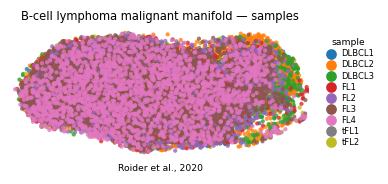

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('B-cell lymphoma malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Roider et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])